# TIME SERIES FORECASTING – LAB EXERCISES 4 & 5

# LAB EXERCISE 4

## ARIMA Model Implementation and Forecasting using Real Datasets

### 1. Aim

To implement an ARIMA model on a real time-series dataset, prepare the series for modelling, fit the model, generate forecasts, evaluate the forecast against unseen test data, and interpret the results.

In [3]:
# LAB EXERCISE 4
# ARIMA MODEL IMPLEMENTATION AND FORECASTING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import mean_absolute_error, mean_squared_error

%matplotlib inline

In [4]:
# 1. Load the real dataset

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)

display(df.head())

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [5]:
# 2. Convert Month into a datetime index

df["Month"] = pd.to_datetime(df["Month"])

df = df.set_index("Month")

# 3. Extract the passenger time series

series = df["Passengers"].astype(float)

display(series.head())

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Name: Passengers, dtype: float64

In [7]:
from statsmodels.tsa.stattools import adfuller

In [8]:
# 5. Test stationarity using the Augmented Dickey-Fuller test

adf_result = adfuller(series)

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF statistic: 0.8153688792060576
p-value: 0.9918802434376411


C:\Users\msc\AppData\Local\Temp\ipykernel_7132\2626695084.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


In [9]:
# 6. First-order differencing

diff_series = series.diff().dropna()

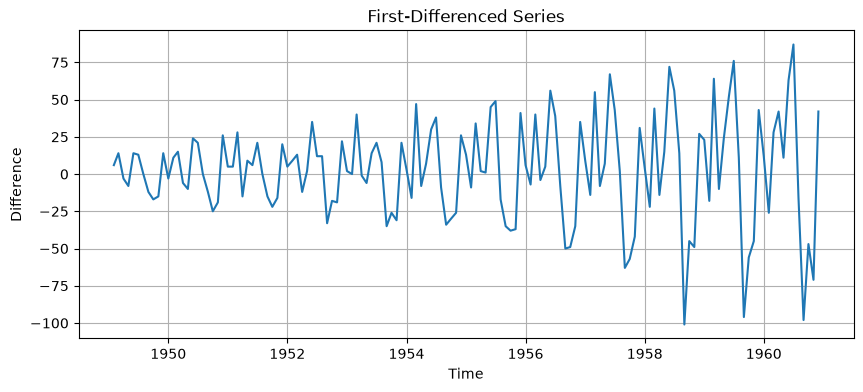

In [10]:
# 7. Plot the differenced series

plt.figure(figsize=(10, 4))
plt.plot(diff_series)
plt.title("First-Differenced Series")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid()
plt.show()

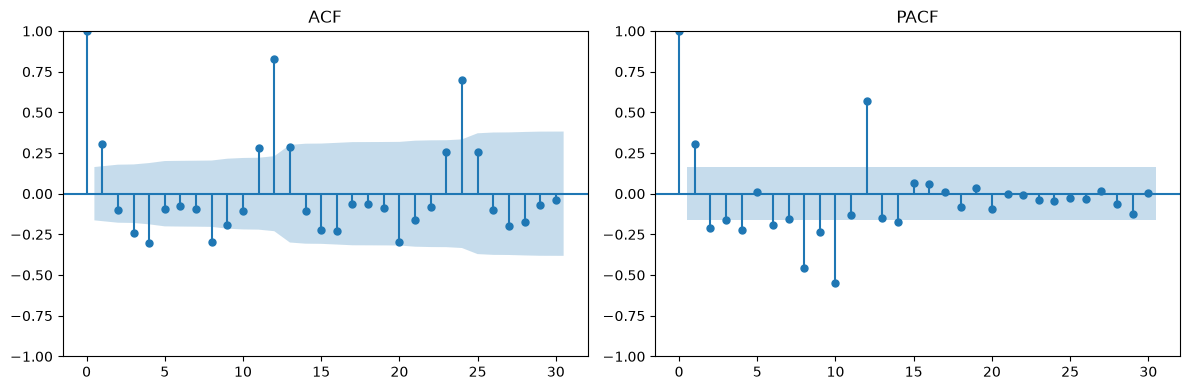

In [11]:
# 8. Plot ACF and PACF of the differenced series

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(diff_series, ax=axes[0], lags=30)
plot_pacf(diff_series, ax=axes[1], lags=30, method="ywm")

axes[0].set_title("ACF")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

In [12]:
# 9. Create train-test split

train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

In [13]:
# 10. Fit an ARIMA model

model = ARIMA(train, order=(2, 1, 2))

model_fit = model.fit()

C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [14]:
# 11. Display the model summary

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Sun, 01 Nov 2026   AIC                           1057.516
Time:                        22:06:06   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

In [15]:
# 12. Forecast exactly as many steps as the test set

forecast = model_fit.forecast(steps=len(test))

In [16]:
# 13. Calculate error metrics

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE :", mae)
print("RMSE:", rmse)

MAE : 63.54531126808658
RMSE: 82.51301131614122


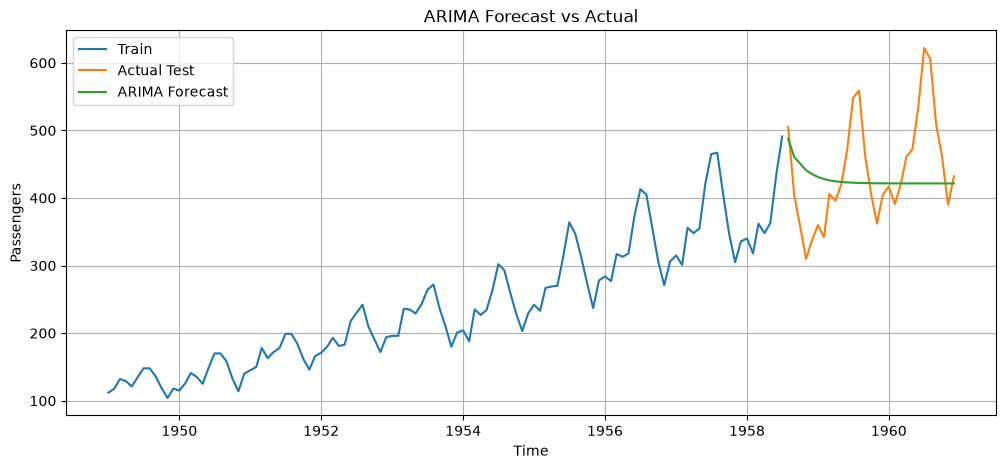

In [17]:
# 14. Plot actual values and forecasts

plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, forecast, label="ARIMA Forecast")

plt.title("ARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("Passengers")

plt.legend()
plt.grid()
plt.show()

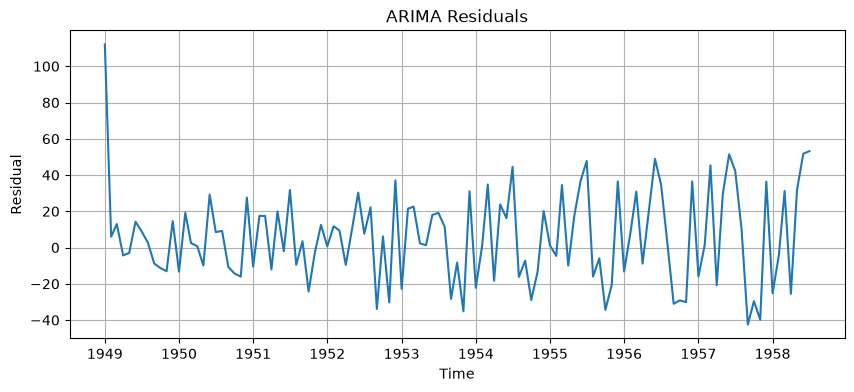

In [18]:
# 15. Plot residuals

residuals = model_fit.resid

plt.figure(figsize=(10, 4))
plt.plot(residuals)
plt.title("ARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid()
plt.show()

## 10. INDEPENDENT TASKS – LAB EXERCISE 4
### ARIMA Model Experimentation and Performance Evaluation

### Introduction

The independent tasks in this exercise focus on exploring the performance and behaviour of ARIMA models under different configurations. The experiments involve modifying model parameters, examining the effect of differencing, evaluating forecasting performance across different time horizons, and analysing model residuals.

These tasks also involve applying the ARIMA methodology to another real-world time-series dataset to understand its practical application beyond the AirPassengers dataset.

### Objectives

1. To compare different ARIMA model configurations using AIC, MAE and RMSE.
2. To examine the effect of differencing on model performance and stationarity.
3. To evaluate forecasting accuracy across different forecast horizons.
4. To analyse residuals and identify possible autocorrelation.
5. To implement ARIMA forecasting using another real-world univariate time-series dataset.

### Tasks Performed

- **Task 4.1:** Change ARIMA order and compare model performance.
- **Task 4.2:** Study the effect of differencing (d = 0 and d = 1).
- **Task 4.3:** Compare forecast horizons of 6, 12 and 24 time steps.
- **Task 4.4:** Perform residual analysis using the ACF plot.
- **Task 4.5:** Implement ARIMA using another real-world dataset.

### Task 4.1 – Change ARIMA Order

**Objective:** To compare the performance of different ARIMA configurations by varying the autoregressive (p), differencing (d), and moving average (q) parameters.

The following four configurations are considered:

1. ARIMA(1,1,1)
2. ARIMA(2,1,1)
3. ARIMA(1,1,2)
4. ARIMA(2,1,2)

Each model is trained using the same training dataset and evaluated against the same test dataset. The performance is compared using Akaike Information Criterion (AIC), Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

In [19]:
# TASK 4.1 - CHANGE ARIMA ORDER

# Define the ARIMA configurations
orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

# Store the comparison results
comparison_results = []

# Fit and evaluate each ARIMA model
for order in orders:

    model = ARIMA(train, order=order)
    model_fit = model.fit()

    forecast = model_fit.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    comparison_results.append({
        "ARIMA Order": str(order),
        "AIC": model_fit.aic,
        "MAE": mae,
        "RMSE": rmse
    })

# Display the comparison table
arima_comparison = pd.DataFrame(comparison_results)

print(arima_comparison.to_string(index=False))

C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-pa

ARIMA Order         AIC       MAE      RMSE
  (1, 1, 1) 1058.245574 85.254156 97.499620
  (2, 1, 1) 1058.647616 60.528995 82.621097
  (1, 1, 2) 1057.327535 62.063473 82.635764
  (2, 1, 2) 1057.516178 63.545311 82.513011


# RESULT AND INTERPRETATION – TASK 4.1

Four ARIMA configurations were evaluated using AIC, MAE and RMSE.

 ARIMA(1,1,2) achieved the lowest AIC value of 1057.328,
 indicating a comparatively better balance between model fit and complexity.

 ARIMA(2,1,1) achieved the lowest MAE value of 60.529,
 indicating the lowest average absolute forecasting error.

 ARIMA(2,1,2) achieved the lowest RMSE value of 82.513,
 indicating the lowest root mean squared forecasting error.

 Therefore, model selection depends on the evaluation criterion.
 ARIMA(2,1,1) is preferred based on MAE, while ARIMA(2,1,2)
 is preferred based on RMSE.

### Task 4.2 – Effect of Differencing (d = 0 and d = 1)

**Objective:** To examine the effect of differencing on ARIMA model performance by comparing models with d = 0 and d = 1.

The following configurations are evaluated:

1. ARIMA(2,0,2) – Model without differencing.
2. ARIMA(2,1,2) – Model with first-order differencing.

Both models are trained using the same training dataset and evaluated using the same testing dataset. Their performance is compared using AIC, MAE and RMSE.

The experiment helps demonstrate the importance of differencing when modelling a non-stationary time series.

In [20]:
# TASK 4.2 - EFFECT OF DIFFERENCING

# Define ARIMA models with different differencing orders
orders = [
    (2, 0, 2),
    (2, 1, 2)
]

# Store comparison results
differencing_results = []

# Fit and evaluate each model
for order in orders:

    model = ARIMA(train, order=order)
    model_fit = model.fit()

    forecast = model_fit.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    differencing_results.append({
        "ARIMA Order": str(order),
        "AIC": model_fit.aic,
        "MAE": mae,
        "RMSE": rmse
    })

# Display comparison table
differencing_comparison = pd.DataFrame(differencing_results)

print(differencing_comparison.to_string(index=False))

C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\msc\AppData\Local\Programs\

ARIMA Order         AIC       MAE       RMSE
  (2, 0, 2) 1074.541307 92.255502 114.902925
  (2, 1, 2) 1057.516178 63.545311  82.513011


C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


# RESULT AND INTERPRETATION – TASK 4.2

 ARIMA(2,0,2) was evaluated without differencing,
 whereas ARIMA(2,1,2) used first-order differencing.

 ARIMA(2,1,2) achieved a lower AIC of 1057.516
 compared to 1074.541 for ARIMA(2,0,2).

 The MAE decreased from 92.256 to 63.545,
 indicating improved average forecasting accuracy.

 The RMSE decreased from 114.903 to 82.513,
 indicating a reduction in forecasting errors.

 Therefore, first-order differencing improved the
 forecasting performance for the non-stationary dataset.

### Task 4.3 – Compare Forecast Horizons

**Objective:** To examine how forecasting performance changes across different prediction horizons.

The ARIMA(2,1,2) model is used to generate forecasts for three different horizons:

1. 6 months
2. 12 months
3. 24 months

The forecasts are compared with the actual test observations using MAE and RMSE.

This experiment helps understand how forecasting errors change as the prediction horizon increases.

In [21]:
# TASK 4.3 - COMPARE FORECAST HORIZONS

# Define forecast horizons
horizons = [6, 12, 24]

# Fit the selected ARIMA model
model = ARIMA(train, order=(2, 1, 2))
model_fit = model.fit()

# Store forecasting results
horizon_results = []

# Evaluate each forecast horizon
for horizon in horizons:

    forecast = model_fit.forecast(steps=horizon)

    actual = test.iloc[:horizon]

    mae = mean_absolute_error(actual, forecast)
    rmse = np.sqrt(mean_squared_error(actual, forecast))

    horizon_results.append({
        "Forecast Horizon (Months)": horizon,
        "MAE": mae,
        "RMSE": rmse
    })

# Display comparison
horizon_comparison = pd.DataFrame(horizon_results)

print(horizon_comparison.to_string(index=False))

 Forecast Horizon (Months)       MAE      RMSE
                         6 77.787203 85.580588
                        12 64.981969 76.774798
                        24 62.102709 79.918805


C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


# RESULT AND INTERPRETATION – TASK 4.3

 The ARIMA(2,1,2) model was evaluated across 6, 12 and 24-month
 forecasting horizons.

 The 6-month forecast produced an MAE of 77.787 and an RMSE of 85.581.

 The 12-month forecast achieved the lowest RMSE of 76.775,
 indicating the lowest root mean squared forecasting error.

 The 24-month forecast achieved the lowest MAE of 62.103,
 indicating the lowest average absolute forecasting error.

 The results do not show a consistent increase in forecasting
 errors with an increase in the prediction horizon.

 Therefore, forecasting performance varies across horizons
 and should be evaluated using multiple performance metrics.

### Task 4.4 – Residual Analysis Using ACF

**Objective:** To analyse the residuals of the ARIMA model using the Autocorrelation Function (ACF) plot.

Residual analysis helps determine whether the fitted model has captured the underlying time-series patterns.

The residual ACF plot is used to identify significant autocorrelation at different lags. Ideally, residuals should behave like white noise, with most autocorrelation values remaining within the confidence intervals.

C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\msc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<Figure size 1200x500 with 0 Axes>

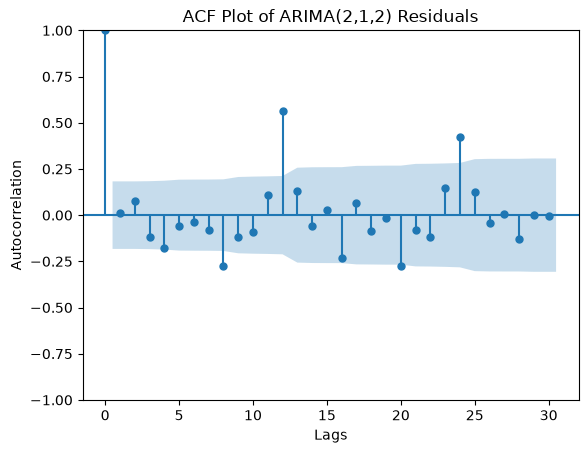

In [22]:
# TASK 4.4 - RESIDUAL ANALYSIS USING ACF

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

# Fit the selected ARIMA model
model = ARIMA(train, order=(2, 1, 2))
model_fit = model.fit()

# Extract residuals
residuals = model_fit.resid

# Plot residual ACF
plt.figure(figsize=(12, 5))
plot_acf(residuals, lags=30)
plt.title("ACF Plot of ARIMA(2,1,2) Residuals")
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.show()

# RESULT AND INTERPRETATION – TASK 4.4

 The residual ACF plot is used to examine the autocorrelation
 remaining in the residuals of the ARIMA(2,1,2) model.

 The vertical spikes represent autocorrelation at different lags.
 The blue confidence bands indicate the approximate significance limits.

 Spikes extending beyond the confidence bands indicate
 statistically significant autocorrelation.

 Ideally, residuals should behave like white noise,
 with most autocorrelation values remaining within the confidence bands.

 This analysis helps determine whether the ARIMA model
 has adequately captured the temporal patterns in the data.

### Task 4.5 – ARIMA Using Another Real-World Dataset

**Objective:** To apply the complete ARIMA forecasting workflow to another real-world univariate time-series dataset.

The Mauna Loa Atmospheric CO₂ dataset contains monthly measurements of atmospheric carbon dioxide concentration. It is used to study changes in atmospheric CO₂ levels over time.

The dataset will be examined for stationarity, differenced when necessary, and modelled using ARIMA. Forecasting performance will be evaluated using MAE and RMSE.

In [23]:
# TASK 4.5 - LOAD ANOTHER REAL-WORLD DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Mauna Loa CO2 dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-mean-temp.csv"

# Display dataset information
df_new = pd.read_csv(url)

print(df_new.head())
print("\nDataset Information:")
print(df_new.info())
print("\nDataset Shape:", df_new.shape)

     Month  Temperature
0  1920-01         40.6
1  1920-02         40.8
2  1920-03         44.4
3  1920-04         46.7
4  1920-05         54.1

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Month        240 non-null    str    
 1   Temperature  240 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.9 KB
None

Dataset Shape: (240, 2)


In [24]:
# TASK 4.5 - DATA PREPROCESSING

# Convert Month column into datetime format
df_new["Month"] = pd.to_datetime(df_new["Month"])

# Set Month as the index
df_new.set_index("Month", inplace=True)

# Set monthly frequency
df_new = df_new.asfreq("MS")

# Extract the temperature time series
temperature_series = df_new["Temperature"].astype(float)

# Display dataset details
print("Dataset Information:")
print(temperature_series.info())

print("\nFirst Five Observations:")
print(temperature_series.head())

print("\nMissing Values:")
print(temperature_series.isnull().sum())

Dataset Information:
<class 'pandas.Series'>
DatetimeIndex: 240 entries, 1920-01-01 to 1939-12-01
Freq: MS
Series name: Temperature
Non-Null Count  Dtype  
--------------  -----  
240 non-null    float64
dtypes: float64(1)
memory usage: 3.8 KB
None

First Five Observations:
Month
1920-01-01    40.6
1920-02-01    40.8
1920-03-01    44.4
1920-04-01    46.7
1920-05-01    54.1
Freq: MS, Name: Temperature, dtype: float64

Missing Values:
0


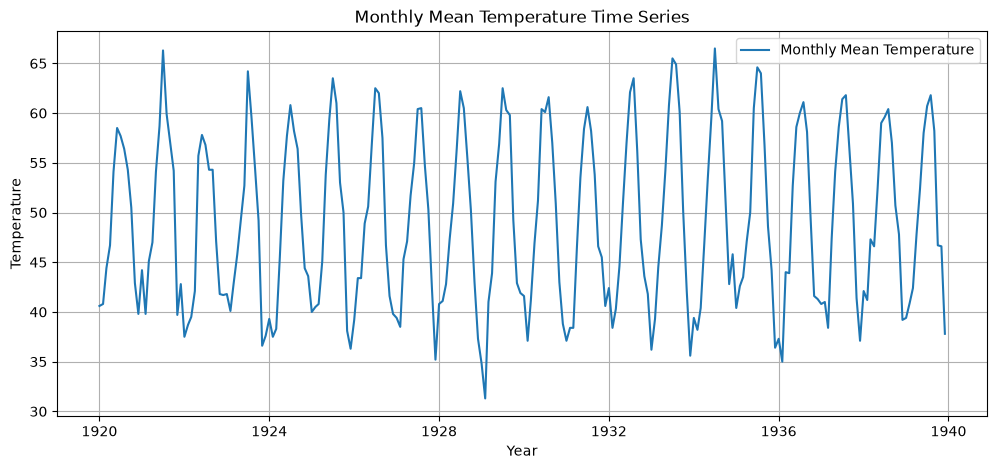

In [25]:
# VISUALISATION OF MONTHLY TEMPERATURE DATA

plt.figure(figsize=(12, 5))

plt.plot(temperature_series, label="Monthly Mean Temperature")

plt.title("Monthly Mean Temperature Time Series")
plt.xlabel("Year")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)

plt.show()

In [26]:
# TASK 4.5 - ADF STATIONARITY TEST

from statsmodels.tsa.stattools import adfuller

# Perform ADF test
adf_result = adfuller(temperature_series.dropna())

# Display test results
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(key, ":", value)

# Interpret the result
if adf_result[1] < 0.05:
    print("\nConclusion: The time series is stationary.")
else:
    print("\nConclusion: The time series is non-stationary.")

ADF Statistic: -3.255492403086335
p-value: 0.016989030222608715
Critical Values:
1% : -3.4597521044060353
5% : -2.874472927517147
10% : -2.5736628197530864

Conclusion: The time series is stationary.


C:\Users\msc\AppData\Local\Temp\ipykernel_7132\3094209207.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(temperature_series.dropna())


# RESULT AND INTERPRETATION – ADF TEST

 The ADF statistic obtained was -3.2555.
 The p-value was 0.01699.

 Since the p-value is less than 0.05, the null hypothesis
 of non-stationarity is rejected.

 The ADF statistic is also lower than the 5% critical value
 of -2.8745.

 Therefore, the monthly temperature time series is stationary
 at the 5% significance level.

 First-order differencing is not required based on this test.

In [27]:
# TASK 4.5 - TRAIN-TEST SPLIT

# Define training size
train_size_new = int(len(temperature_series) * 0.80)

# Split the dataset
train_new = temperature_series.iloc[:train_size_new]
test_new = temperature_series.iloc[train_size_new:]

# Display dataset sizes
print("Total Observations:", len(temperature_series))
print("Training Observations:", len(train_new))
print("Testing Observations:", len(test_new))

Total Observations: 240
Training Observations: 192
Testing Observations: 48


In [28]:
# TASK 4.5 - FIT ARIMA MODEL

# Define ARIMA model
model_new = ARIMA(train_new, order=(2, 0, 2))

# Fit the model
model_fit_new = model_new.fit()

# Display model summary
print(model_fit_new.summary())

                               SARIMAX Results                                
Dep. Variable:            Temperature   No. Observations:                  192
Model:                 ARIMA(2, 0, 2)   Log Likelihood                -462.461
Date:                Sun, 01 Nov 2026   AIC                            936.922
Time:                        22:19:45   BIC                            956.467
Sample:                    01-01-1920   HQIC                           944.838
                         - 12-01-1935                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         48.9498      0.208    235.579      0.000      48.543      49.357
ar.L1          1.7322      0.001   1773.043      0.000       1.730       1.734
ar.L2         -0.9999      0.000  -2582.157      0.0

In [29]:
# TASK 4.5 - GENERATE FORECASTS

# Generate forecasts for the testing period
forecast_new = model_fit_new.forecast(steps=len(test_new))

# Display forecast values
print("Forecasted Values:")
print(forecast_new)

Forecasted Values:
1936-01-01    36.341410
1936-02-01    36.686577
1936-03-01    40.314573
1936-04-01    46.253752
1936-05-01    52.913889
1936-06-01    58.511966
1936-07-01    61.549512
1936-08-01    61.213707
1936-09-01    57.594887
1936-10-01    51.662242
1936-11-01    45.004247
1936-12-01    39.403348
1937-01-01    36.358771
1937-02-01    36.685220
1937-03-01    40.294863
1937-04-01    46.220968
1937-05-01    52.876809
1937-06-01    58.480517
1937-07-01    61.532112
1937-08-01    61.215012
1937-09-01    57.614546
1937-10-01    51.694989
1937-11-01    45.041314
1937-12-01    39.434812
1938-01-01    36.376210
1938-02-01    36.683967
1938-03-01    40.275256
1938-04-01    46.188258
1938-05-01    52.839755
1938-06-01    58.449038
1938-07-01    61.514635
1938-08-01    61.216214
1938-09-01    57.634102
1938-10-01    51.727662
1938-11-01    45.078356
1938-12-01    39.466305
1939-01-01    36.393725
1939-02-01    36.682817
1939-03-01    40.255751
1939-04-01    46.155622
1939-05-01    52.8027

In [30]:
# TASK 4.5 - MODEL EVALUATION

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate evaluation metrics
mae_new = mean_absolute_error(test_new, forecast_new)
rmse_new = np.sqrt(mean_squared_error(test_new, forecast_new))

# Display results
print("ARIMA Model Evaluation")
print("----------------------")
print("MAE:", mae_new)
print("RMSE:", rmse_new)

ARIMA Model Evaluation
----------------------
MAE: 1.8446236831332659
RMSE: 2.4756146076818446


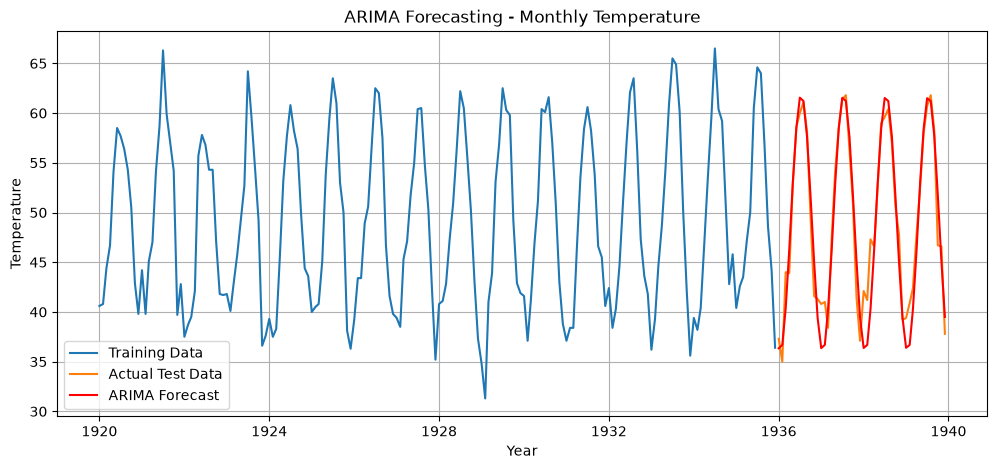

In [31]:
# TASK 4.5 - ACTUAL VS FORECASTED VALUES

plt.figure(figsize=(12, 5))

plt.plot(train_new.index, train_new, label="Training Data")
plt.plot(test_new.index, test_new, label="Actual Test Data")
plt.plot(forecast_new.index, forecast_new, label="ARIMA Forecast", color="red")

plt.title("ARIMA Forecasting - Monthly Temperature")
plt.xlabel("Year")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)

plt.show()

# RESULT AND INTERPRETATION – TASK 4.5

 The monthly mean temperature dataset contains 240 observations.
 An 80:20 split was used, resulting in 192 training observations
 and 48 testing observations.

 The ADF test produced a p-value of 0.01699, indicating
 that the original time series is stationary at the 5% level.

 ARIMA(2,0,2) was selected for modelling without differencing.

 The model achieved an AIC of 936.922.

 The forecasting evaluation produced:
 MAE = 1.8446
 RMSE = 2.4756

 The Ljung-Box test produced a p-value of 0.00,
 indicating significant residual autocorrelation.

 The Jarque-Bera test produced a p-value of 0.65,
 showing no significant evidence against residual normality.

 Therefore, ARIMA(2,0,2) provides forecasts with relatively
 low errors, although some temporal structure remains
 unexplained in the residuals.

 This experiment demonstrates the application of ARIMA
 forecasting to a different real-world time-series dataset.

# LAB EXERCISE 5
## Seasonal ARIMA (SARIMA) Forecasting for Seasonal Datasets

### 1. Aim

To implement a Seasonal ARIMA model for a dataset containing recurring seasonal patterns, identify the seasonal structure, fit a SARIMA model, generate forecasts, and evaluate the predictions.

### 2. Introduction

SARIMA extends the traditional ARIMA model by explicitly incorporating seasonal components. It is particularly useful for time-series datasets that exhibit recurring patterns over fixed intervals.

The AirPassengers dataset is used in this experiment because it contains monthly international airline passenger counts with a recurring yearly seasonal pattern.

The seasonal period is set to 12 because the dataset contains monthly observations with annual seasonality.

In [32]:
# LAB 5 - SARIMA FORECASTING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [34]:
# 1. LOAD THE MONTHLY AIRPASSENGERS DATASET

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)

# Convert Month into datetime format
df["Month"] = pd.to_datetime(df["Month"])

# Set Month as the index
df = df.set_index("Month")

# Force monthly frequency
series = df["Passengers"].asfreq("MS").astype(float)

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nFirst Five Observations:")
print(series.head())

print("\nLast Five Observations:")
print(series.tail())

Dataset Shape: (144, 1)

First Five Observations:
Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64

Last Five Observations:
Month
1960-08-01    606.0
1960-09-01    508.0
1960-10-01    461.0
1960-11-01    390.0
1960-12-01    432.0
Freq: MS, Name: Passengers, dtype: float64


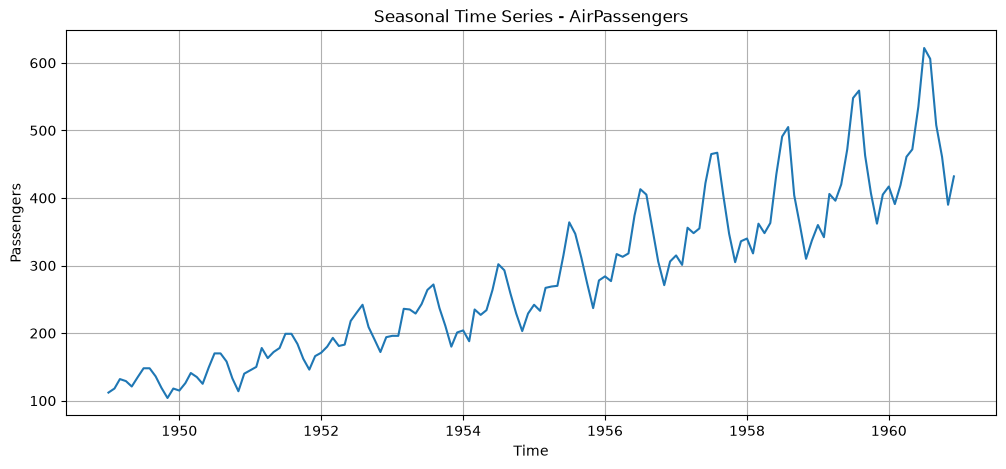

In [35]:
# 2. PLOT THE SEASONAL TIME SERIES

plt.figure(figsize=(12, 5))

plt.plot(series)

plt.title("Seasonal Time Series - AirPassengers")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid()

plt.show()

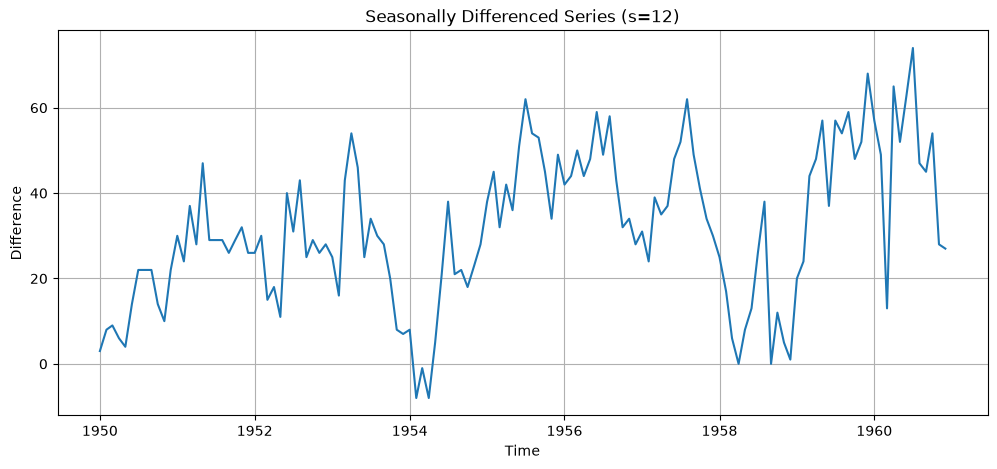

In [36]:
# 3. SEASONAL DIFFERENCING

seasonal_diff = series.diff(12).dropna()

plt.figure(figsize=(12, 5))

plt.plot(seasonal_diff)

plt.title("Seasonally Differenced Series (s=12)")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid()

plt.show()

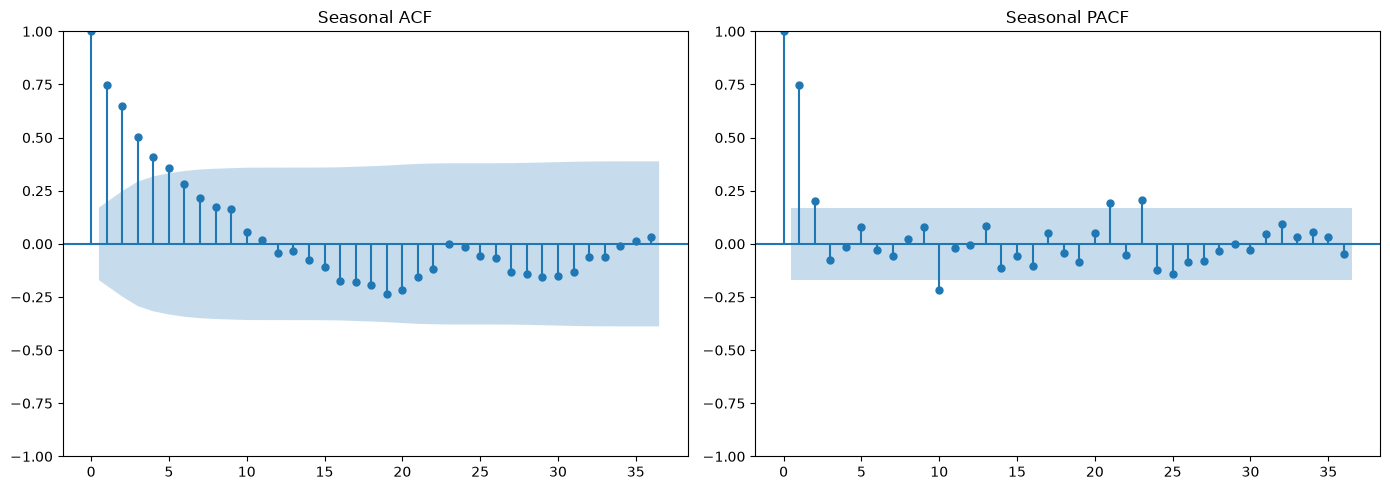

In [37]:
# 4. PLOT ACF AND PACF

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(seasonal_diff, ax=axes[0], lags=36)
plot_pacf(seasonal_diff, ax=axes[1], lags=36, method="ywm")

axes[0].set_title("Seasonal ACF")
axes[1].set_title("Seasonal PACF")

plt.tight_layout()
plt.show()

In [38]:
# 5. TRAIN-TEST SPLIT

train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Training Data Size:", len(train))
print("Testing Data Size:", len(test))

print("\nTraining Period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting Period:")
print(test.index.min(), "to", test.index.max())

Training Data Size: 115
Testing Data Size: 29

Training Period:
1949-01-01 00:00:00 to 1958-07-01 00:00:00

Testing Period:
1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [39]:
# 6. FIT THE SARIMA MODEL

model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Sun, 01 Nov 2026   AIC                            657.601
Time:                                    22:33:28   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

In [40]:
# 7. GENERATE SARIMA FORECAST

forecast = model_fit.forecast(steps=len(test))

print("SARIMA Forecast:")
print(forecast)

SARIMA Forecast:
1958-08-01    491.338985
1958-09-01    429.776735
1958-10-01    371.988814
1958-11-01    331.255533
1958-12-01    361.568724
1959-01-01    366.493950
1959-02-01    344.255190
1959-03-01    389.316446
1959-04-01    375.294294
1959-05-01    390.174098
1959-06-01    461.842240
1959-07-01    517.654618
1959-08-01    518.023652
1959-09-01    456.400496
1959-10-01    398.463866
1959-11-01    357.541000
1959-12-01    387.831228
1960-01-01    392.593673
1960-02-01    370.225624
1960-03-01    414.957264
1960-04-01    400.777462
1960-05-01    415.856673
1960-06-01    487.577916
1960-07-01    543.578743
1960-08-01    543.855427
1960-09-01    482.326459
1960-10-01    424.412571
1960-11-01    383.628197
1960-12-01    413.894690
Freq: MS, Name: predicted_mean, dtype: float64


In [41]:
# 8. MODEL EVALUATION

mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(mean_squared_error(test, forecast))

print("SARIMA Model Evaluation")
print("-----------------------")
print("MAE :", mae)
print("RMSE:", rmse)

SARIMA Model Evaluation
-----------------------
MAE : 25.268045653271287
RMSE: 31.78729745523361


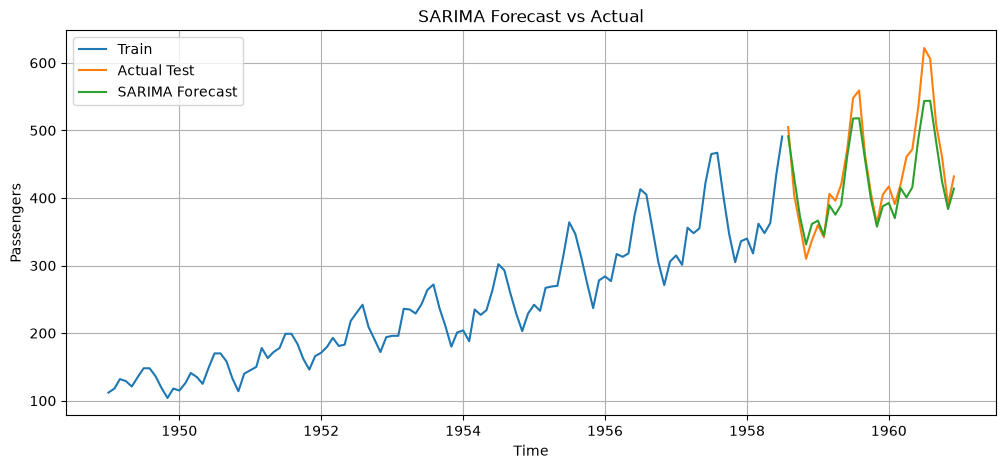

In [42]:
# 9. ACTUAL VS SARIMA FORECAST

plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, forecast, label="SARIMA Forecast")

plt.title("SARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("Passengers")

plt.legend()
plt.grid()
plt.show()

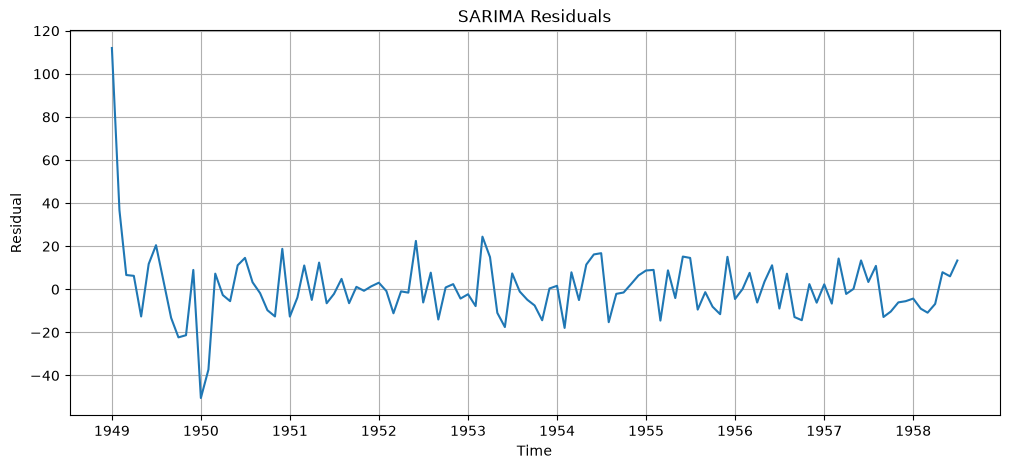

In [43]:
# 10. SARIMA RESIDUAL ANALYSIS

residuals = model_fit.resid

plt.figure(figsize=(12, 5))

plt.plot(residuals)

plt.title("SARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")

plt.grid()
plt.show()

# Interpretation:
Residuals represent the difference between observed and fitted values
A good forecasting model should ideally produce residuals that fluctuate
 randomly around zero without any noticeable trend or systematic pattern.
 Residual analysis helps assess whether the SARIMA model has captured
 the important patterns in the training dataset.

# Independent Task 5.1 — Compare SARIMA Orders

**Objective:**

To compare different SARIMA model configurations using the same training and testing datasets and evaluate their forecasting performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

SARIMA models contain both non-seasonal parameters (p, d, q) and seasonal parameters (P, D, Q, s). Different combinations of these parameters can influence the model's ability to capture trends and recurring seasonal patterns.

In this task, three SARIMA configurations are compared using the same training and testing datasets. AIC, MAE and RMSE are used to assess model performance.

- **AIC:** Measures model fit while penalising complexity. Lower values are generally preferred when comparing models fitted to the same data.
- **MAE:** Measures the average absolute difference between actual and predicted values.
- **RMSE:** Measures forecasting errors while giving greater weight to larger errors.

The model with lower MAE and RMSE demonstrates better forecasting accuracy on the selected test dataset.

In [44]:
# INDEPENDENT TASK 5.1 - COMPARE SARIMA ORDERS

sarima_configs = {
    "SARIMA(1,1,1)(1,1,1,12)": ((1, 1, 1), (1, 1, 1, 12)),
    "SARIMA(1,1,1)(0,1,1,12)": ((1, 1, 1), (0, 1, 1, 12)),
    "SARIMA(2,1,1)(1,1,1,12)": ((2, 1, 1), (1, 1, 1, 12))
}

sarima_results = []

for name, orders in sarima_configs.items():

    model_temp = SARIMAX(
        train,
        order=orders[0],
        seasonal_order=orders[1],
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    model_fit_temp = model_temp.fit(disp=False)

    forecast_temp = model_fit_temp.forecast(steps=len(test))

    mae_temp = mean_absolute_error(test, forecast_temp)

    rmse_temp = np.sqrt(mean_squared_error(test, forecast_temp))

    sarima_results.append({
        "Model": name,
        "AIC": model_fit_temp.aic,
        "MAE": mae_temp,
        "RMSE": rmse_temp
    })

sarima_comparison = pd.DataFrame(sarima_results)

print("SARIMA MODEL COMPARISON")
print(sarima_comparison.to_string(index=False))

SARIMA MODEL COMPARISON
                  Model        AIC       MAE      RMSE
SARIMA(1,1,1)(1,1,1,12) 657.601346 25.268046 31.787297
SARIMA(1,1,1)(0,1,1,12) 659.332685 23.367858 29.923085
SARIMA(2,1,1)(1,1,1,12) 659.252153 26.495904 32.989593


**Interpretation:**

The comparison of different SARIMA configurations helps identify how changes in seasonal and non-seasonal parameters influence forecasting performance. A lower MAE indicates a smaller average absolute prediction error, while a lower RMSE indicates fewer large forecasting errors. AIC provides an additional measure of model fit and complexity. The configuration with the lowest MAE and RMSE can be considered the most accurate among the tested models on the selected test dataset. The results also demonstrate that selecting appropriate seasonal and non-seasonal parameters is important for effective time-series forecasting. Different SARIMA configurations were implemented and evaluated using an identical train-test split. Their AIC, MAE and RMSE values were compared to understand the effect of parameter selection on forecasting performance. This experiment demonstrates the importance of comparing multiple SARIMA configurations rather than assuming that a single model is universally optimal.

### Independent Task 5.2 — Seasonal Period

**Objective:**

To understand the importance of selecting an appropriate seasonal period (s) in SARIMA modelling.

**Theory:**

The seasonal period (s) represents the number of observations in one complete seasonal cycle.

For monthly data with annual seasonality, s = 12 because the seasonal pattern repeats every twelve months. Seasonal differencing compares an observation with the corresponding observation from the previous seasonal cycle.

Examples:

- **s = 12:** Monthly observations with yearly seasonality, such as monthly airline passenger numbers.
- **s = 7:** Daily observations with weekly seasonality, such as electricity consumption or website traffic that follows a weekly pattern.
- **s = 24:** Hourly observations with daily seasonality, such as electricity demand or traffic volume that repeats every 24 hours.

Choosing the correct seasonal period allows SARIMA to capture recurring patterns at the appropriate interval.

In [45]:
# INDEPENDENT TASK 5.2 - UNDERSTANDING SEASONAL PERIOD

seasonal_periods = {
    "Monthly data - Annual seasonality": 12,
    "Daily data - Weekly seasonality": 7,
    "Hourly data - Daily seasonality": 24
}

for description, period in seasonal_periods.items():
    print(description, "-> Seasonal Period (s) =", period)

Monthly data - Annual seasonality -> Seasonal Period (s) = 12
Daily data - Weekly seasonality -> Seasonal Period (s) = 7
Hourly data - Daily seasonality -> Seasonal Period (s) = 24


**Interpretation:**

The seasonal period depends on the frequency of the observations and the duration of the repeating pattern. In the AirPassengers dataset, observations are recorded monthly and the passenger pattern repeats annually. Therefore, s = 12 is appropriate. For daily data exhibiting weekly patterns, s = 7 is suitable, while hourly data with daily patterns can use s = 24. Selecting an appropriate seasonal period helps the SARIMA model identify and represent recurring seasonal behaviour. **Conclusion:**

The experiment demonstrates that the seasonal period must be selected according to the frequency and recurring pattern of the dataset. An appropriate seasonal period enables SARIMA to model seasonal relationships more effectively.

### Independent Task 5.3 — ARIMA vs SARIMA

**Objective:**

To compare the forecasting performance of ARIMA and SARIMA models on the same seasonal dataset and test period.

**Theory:**

ARIMA models capture non-seasonal time-series relationships using autoregressive, differencing and moving-average components. However, they do not explicitly represent seasonal patterns.

SARIMA extends ARIMA by including seasonal autoregressive, differencing and moving-average components. These additional parameters allow the model to capture recurring seasonal behaviour.

In this task, the ARIMA(2,1,2) model from Lab Exercise 4 is compared with the SARIMA(1,1,1)(1,1,1,12) model from Lab Exercise 5. Both models use the same training and testing datasets to ensure a fair comparison.

ARIMA VS SARIMA COMPARISON
                  Model       MAE      RMSE
           ARIMA(2,1,2) 63.545311 82.513011
SARIMA(1,1,1)(1,1,1,12) 25.268046 31.787297


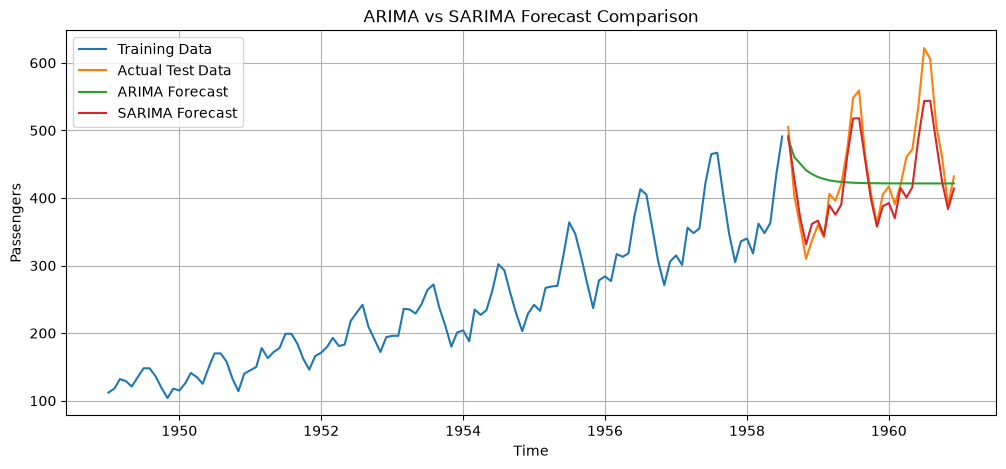

In [46]:
# INDEPENDENT TASK 5.3 - ARIMA VS SARIMA

from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA model
arima_model = ARIMA(
    train,
    order=(2, 1, 2)
)

arima_fit = arima_model.fit()

# Generate ARIMA forecast
arima_forecast = arima_fit.forecast(steps=len(test))

# Fit SARIMA model
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

# Generate SARIMA forecast
sarima_forecast = sarima_fit.forecast(steps=len(test))

# Calculate evaluation metrics
arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))

sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_forecast))

# Display comparison
comparison = pd.DataFrame({
    "Model": ["ARIMA(2,1,2)", "SARIMA(1,1,1)(1,1,1,12)"],
    "MAE": [arima_mae, sarima_mae],
    "RMSE": [arima_rmse, sarima_rmse]
})

print("ARIMA VS SARIMA COMPARISON")
print(comparison.to_string(index=False))

# Plot comparison
plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Test Data")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast")
plt.plot(test.index, sarima_forecast, label="SARIMA Forecast")

plt.title("ARIMA vs SARIMA Forecast Comparison")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

**Interpretation:**

ARIMA and SARIMA are compared using the same training and testing observations. MAE and RMSE indicate the forecasting errors of each model. ARIMA models non-seasonal relationships, whereas SARIMA additionally incorporates seasonal components. Comparing their forecasts helps determine whether explicitly modelling annual seasonality improves prediction accuracy for the AirPassengers dataset. The model with lower MAE and RMSE demonstrates better performance on the selected test period. **Conclusion:**

The experiment compares ARIMA and SARIMA forecasting performance on a seasonal dataset. It demonstrates the importance of explicitly modelling seasonality when recurring patterns are present. The final model selection should be based on actual test-set errors and forecast behaviour.

### Independent Task 5.4 — Seasonal Differencing

**Objective:**

To compare SARIMA models with seasonal differencing orders D = 0 and D = 1 and understand the effect of seasonal differencing on forecasting performance.

**Theory:**

Seasonal differencing removes or reduces repeating seasonal patterns by subtracting an observation from the corresponding observation in the previous seasonal cycle.

The seasonal differencing equation is:

y′ₜ = yₜ − yₜ₋ₛ

For monthly data with annual seasonality, s = 12.

- **D = 0:** No seasonal differencing is applied by the model.
- **D = 1:** One order of seasonal differencing is applied to account for recurring seasonal patterns.

Comparing these configurations helps evaluate whether seasonal differencing improves the forecasting performance of the model.

SEASONAL DIFFERENCING COMPARISON
     Model       MAE      RMSE
SARIMA D=0 18.697301 22.399168
SARIMA D=1 25.268046 31.787297


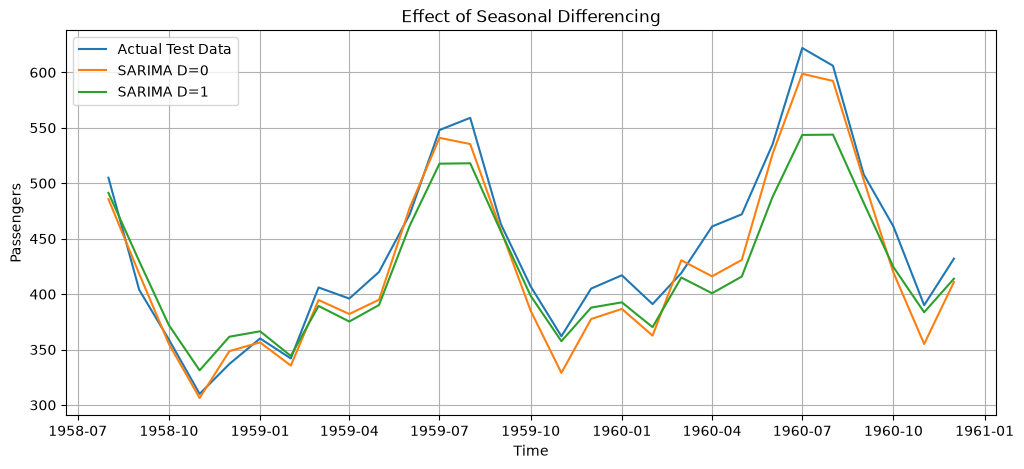

In [47]:
# INDEPENDENT TASK 5.4 - COMPARE D=0 AND D=1

# SARIMA model with D=0
model_D0 = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fit_D0 = model_D0.fit(disp=False)

forecast_D0 = fit_D0.forecast(steps=len(test))

# SARIMA model with D=1
model_D1 = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fit_D1 = model_D1.fit(disp=False)

forecast_D1 = fit_D1.forecast(steps=len(test))

# Calculate evaluation metrics
mae_D0 = mean_absolute_error(test, forecast_D0)
rmse_D0 = np.sqrt(mean_squared_error(test, forecast_D0))

mae_D1 = mean_absolute_error(test, forecast_D1)
rmse_D1 = np.sqrt(mean_squared_error(test, forecast_D1))

# Display comparison
D_comparison = pd.DataFrame({
    "Model": ["SARIMA D=0", "SARIMA D=1"],
    "MAE": [mae_D0, mae_D1],
    "RMSE": [rmse_D0, rmse_D1]
})

print("SEASONAL DIFFERENCING COMPARISON")
print(D_comparison.to_string(index=False))

# Plot forecast comparison
plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label="Actual Test Data")
plt.plot(test.index, forecast_D0, label="SARIMA D=0")
plt.plot(test.index, forecast_D1, label="SARIMA D=1")

plt.title("Effect of Seasonal Differencing")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

**Interpretation:**

The two SARIMA configurations differ in their seasonal differencing order. The D = 0 model does not apply seasonal differencing, while the D = 1 model applies one seasonal difference to account for recurring annual patterns. Their MAE and RMSE values indicate how seasonal differencing affects forecasting accuracy. The forecast comparison graph provides a visual understanding of how both configurations follow the actual passenger values. The model with lower test-set errors demonstrates better forecasting performance for this experiment. **Conclusion:**

The experiment demonstrates how seasonal differencing influences SARIMA forecasting. Selecting an appropriate seasonal differencing order is important for modelling recurring patterns without introducing unnecessary transformations.

### Independent Task 5.5 — Different Seasonal Dataset

**Objective:**

To implement a SARIMA model on a different real-world seasonal dataset, identify its seasonal period and evaluate its forecasting performance.

**Dataset:**

Monthly Mean Temperature Dataset.

**Source:**

https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-mean-temp.csv

**Sampling Frequency:** Monthly.

**Seasonal Period:** s = 12.

**Justification:**

The dataset contains monthly temperature observations. Since temperature can exhibit recurring annual patterns, a seasonal period of 12 is selected to represent the yearly cycle. SARIMA is used to model the seasonal behaviour and generate forecasts for unseen observations.

In [48]:
# INDEPENDENT TASK 5.5 - LOAD DIFFERENT SEASONAL DATASET

temperature_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-mean-temp.csv"

temp_df = pd.read_csv(temperature_url)

temp_df["Month"] = pd.to_datetime(temp_df["Month"])

temp_df = temp_df.set_index("Month")

temperature_series = temp_df["Temperature"].asfreq("MS").astype(float)

print("Dataset Shape:", temp_df.shape)

print("\nFirst Five Observations:")
print(temperature_series.head())

print("\nLast Five Observations:")
print(temperature_series.tail())

Dataset Shape: (240, 1)

First Five Observations:
Month
1920-01-01    40.6
1920-02-01    40.8
1920-03-01    44.4
1920-04-01    46.7
1920-05-01    54.1
Freq: MS, Name: Temperature, dtype: float64

Last Five Observations:
Month
1939-08-01    61.8
1939-09-01    58.2
1939-10-01    46.7
1939-11-01    46.6
1939-12-01    37.8
Freq: MS, Name: Temperature, dtype: float64


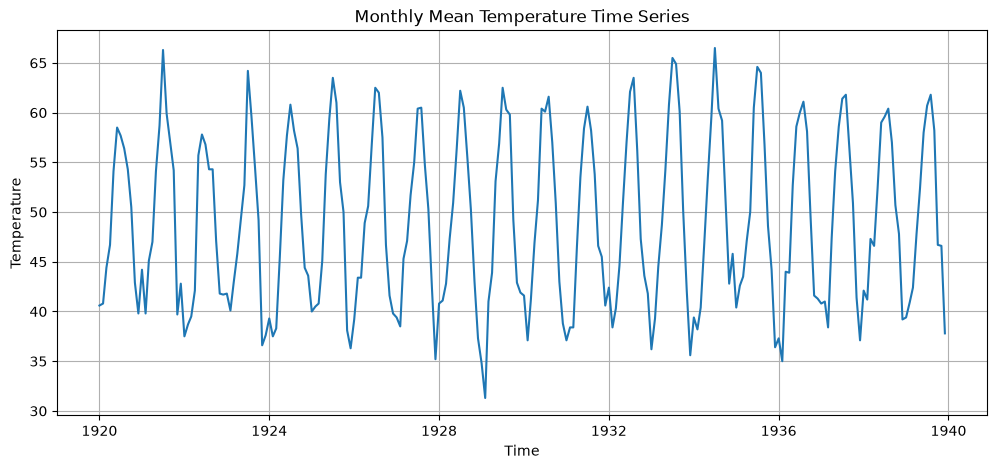

In [49]:
# PLOT MONTHLY TEMPERATURE SERIES

plt.figure(figsize=(12, 5))

plt.plot(temperature_series)

plt.title("Monthly Mean Temperature Time Series")
plt.xlabel("Time")
plt.ylabel("Temperature")

plt.grid()
plt.show()

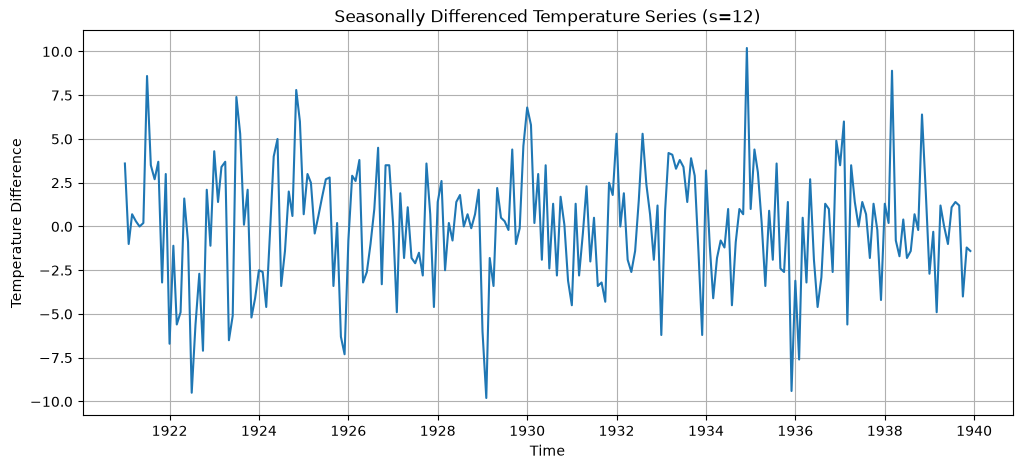

In [50]:
# APPLY SEASONAL DIFFERENCING WITH s=12

temperature_seasonal_diff = temperature_series.diff(12).dropna()

plt.figure(figsize=(12, 5))

plt.plot(temperature_seasonal_diff)

plt.title("Seasonally Differenced Temperature Series (s=12)")
plt.xlabel("Time")
plt.ylabel("Temperature Difference")

plt.grid()
plt.show()

In [51]:
# SPLIT TEMPERATURE DATASET INTO TRAINING AND TESTING

temp_train_size = int(len(temperature_series) * 0.80)

temp_train = temperature_series.iloc[:temp_train_size]

temp_test = temperature_series.iloc[temp_train_size:]

print("Training Data Size:", len(temp_train))
print("Testing Data Size:", len(temp_test))

print("\nTraining Period:")
print(temp_train.index.min(), "to", temp_train.index.max())

print("\nTesting Period:")
print(temp_test.index.min(), "to", temp_test.index.max())

Training Data Size: 192
Testing Data Size: 48

Training Period:
1920-01-01 00:00:00 to 1935-12-01 00:00:00

Testing Period:
1936-01-01 00:00:00 to 1939-12-01 00:00:00


In [52]:
# FIT SARIMA MODEL ON TEMPERATURE DATA

temperature_model = SARIMAX(
    temp_train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

temperature_model_fit = temperature_model.fit(disp=False)

print(temperature_model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                        Temperature   No. Observations:                  192
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 12)   Log Likelihood                -413.685
Date:                            Sun, 01 Nov 2026   AIC                            837.370
Time:                                    22:42:24   BIC                            853.279
Sample:                                01-01-1920   HQIC                           843.822
                                     - 12-01-1935                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4817      0.246      1.960      0.050     9.3e-05       0.963
ma.L1         -0.2272      0.283   

In [53]:
# GENERATE TEMPERATURE FORECAST

temperature_forecast = temperature_model_fit.forecast(
    steps=len(temp_test)
)

print("Temperature Forecast:")
print(temperature_forecast)

Temperature Forecast:
1936-01-01    38.912915
1936-02-01    39.012954
1936-03-01    42.164960
1936-04-01    46.913373
1936-05-01    52.884734
1936-06-01    59.097844
1936-07-01    63.611144
1936-08-01    61.859516
1936-09-01    57.432166
1936-10-01    49.996681
1936-11-01    43.171019
1936-12-01    40.132196
1937-01-01    39.871845
1937-02-01    39.513516
1937-03-01    42.450663
1937-04-01    47.101747
1937-05-01    53.033258
1937-06-01    59.233541
1937-07-01    63.743563
1937-08-01    61.982867
1937-09-01    57.544311
1937-10-01    50.093310
1937-11-01    43.253984
1937-12-01    40.209055
1938-01-01    39.948059
1938-02-01    39.588975
1938-03-01    42.531691
1938-04-01    47.191634
1938-05-01    53.134454
1938-06-01    59.346563
1938-07-01    63.865189
1938-08-01    62.101132
1938-09-01    57.654107
1938-10-01    50.188889
1938-11-01    43.336514
1938-12-01    40.285775
1939-01-01    40.024281
1939-02-01    39.664511
1939-03-01    42.612842
1939-04-01    47.281676
1939-05-01    53.2

In [54]:
# EVALUATE TEMPERATURE SARIMA MODEL

temperature_mae = mean_absolute_error(
    temp_test,
    temperature_forecast
)

temperature_rmse = np.sqrt(
    mean_squared_error(temp_test, temperature_forecast)
)

print("Temperature SARIMA Evaluation")
print("-----------------------------")
print("MAE :", temperature_mae)
print("RMSE:", temperature_rmse)

Temperature SARIMA Evaluation
-----------------------------
MAE : 1.6370229580201763
RMSE: 2.0968071351234747


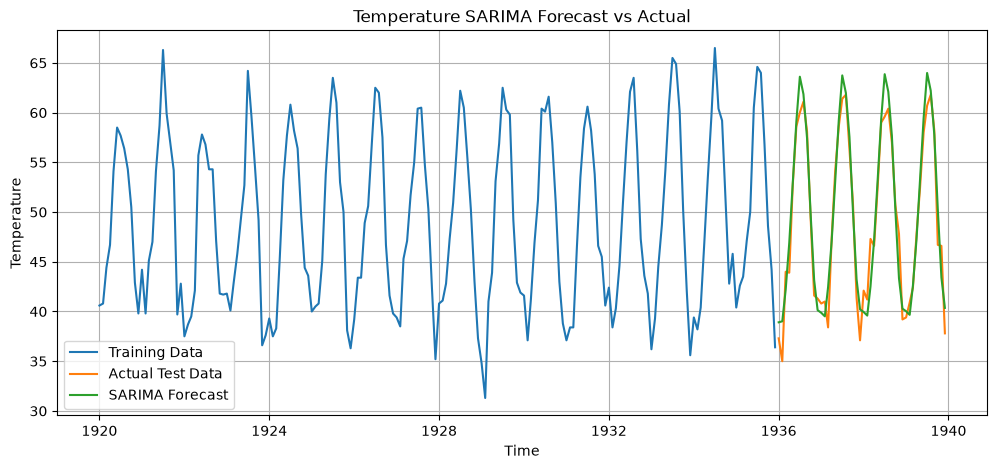

In [55]:
# PLOT ACTUAL VS FORECAST TEMPERATURE

plt.figure(figsize=(12, 5))

plt.plot(temp_train.index, temp_train, label="Training Data")

plt.plot(temp_test.index, temp_test, label="Actual Test Data")

plt.plot(temp_test.index, temperature_forecast, label="SARIMA Forecast")

plt.title("Temperature SARIMA Forecast vs Actual")

plt.xlabel("Time")
plt.ylabel("Temperature")

plt.legend()
plt.grid()
plt.show()

**Interpretation:**

The Monthly Mean Temperature dataset was used to demonstrate SARIMA forecasting on a different seasonal time series. The observations were recorded monthly, and a seasonal period of 12 was selected to represent annual temperature patterns. Seasonal differencing was applied for exploratory analysis. The dataset was divided chronologically into training and testing sets, and a SARIMA model was fitted using the training observations. Forecasting performance was evaluated using MAE and RMSE. The actual-versus-forecast graph was used to visually assess how closely the model followed the observed temperature values. **Conclusion:**

A SARIMA model was implemented on a different real-world seasonal dataset. The experiment demonstrated the application of seasonal forecasting to monthly temperature observations using a seasonal period of 12. The model's forecasting performance was evaluated using MAE and RMSE, demonstrating how SARIMA can be applied to datasets beyond airline passenger numbers.